**Understanding to the dataset**

In [305]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score

os.makedirs("outputs", exist_ok=True)


In [306]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [307]:
df = pd.read_csv(
    "/content/drive/MyDrive/proj ml/originaldataset.csv",
    skipinitialspace=True
)
#upload the data
#skip the spaces in the dataset

In [308]:
 df.shape

(79330, 31)

In [309]:
df.head()

,IsCanceled,LeadTime,ArrivalDateYear,ArrivalDateMonth,ArrivalDateWeekNumber,ArrivalDateDayOfMonth,StaysInWeekendNights,StaysInWeekNights,Adults,Children,...,DepositType,Agent,Company,DaysInWaitingList,CustomerType,ADR,RequiredCarParkingSpaces,TotalOfSpecialRequests,ReservationStatus,ReservationStatusDate
0,0,6,2015,July,27,1,0,2,1,0.0,...,No Deposit,6.0,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-03
1,1,88,2015,July,27,1,0,4,2,0.0,...,No Deposit,9.0,NaN,0,Transient,76.5,0,1,Canceled,2015-07-01
2,1,65,2015,July,27,1,0,4,1,0.0,...,No Deposit,9.0,NaN,0,Transient,68.0,0,1,Canceled,2015-04-30
3,1,92,2015,July,27,1,2,4,2,0.0,...,No Deposit,9.0,NaN,0,Transient,76.5,0,2,Canceled,2015-06-23
4,1,100,2015,July,27,2,0,2,2,0.0,...,No Deposit,9.0,NaN,0,Transient,76.5,0,1,Canceled,2015-04-02


In [310]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 79330 entries, 0 to 79329
Data columns (total 31 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   IsCanceled                   79330 non-null  int64  
 1   LeadTime                     79330 non-null  int64  
 2   ArrivalDateYear              79330 non-null  int64  
 3   ArrivalDateMonth             79330 non-null  object 
 4   ArrivalDateWeekNumber        79330 non-null  int64  
 5   ArrivalDateDayOfMonth        79330 non-null  int64  
 6   StaysInWeekendNights         79330 non-null  int64  
 7   StaysInWeekNights            79330 non-null  int64  
 8   Adults                       79330 non-null  int64  
 9   Children                     79326 non-null  float64
 10  Babies                       79330 non-null  int64  
 11  Meal                         79330 non-null  object 
 12  Country                      79306 non-null  object 
 13  MarketSegment   

In [311]:

display(df.describe())




,IsCanceled,LeadTime,ArrivalDateYear,ArrivalDateWeekNumber,ArrivalDateDayOfMonth,StaysInWeekendNights,StaysInWeekNights,Adults,Children,Babies,IsRepeatedGuest,PreviousCancellations,PreviousBookingsNotCanceled,BookingChanges,Agent,Company,DaysInWaitingList,ADR,RequiredCarParkingSpaces,TotalOfSpecialRequests
count,79330.000000,79330.000000,79330.000000,79330.000000,79330.000000,79330.000000,79330.000000,79330.000000,79326.000000,79330.000000,79330.000000,79330.000000,79330.000000,79330.000000,71199.000000,3689.000000,79330.000000,79330.000000,79330.000000,79330.000000
mean,0.417270,109.735724,2016.174285,27.177449,15.786625,0.795185,2.182957,1.850977,0.091370,0.004941,0.025615,0.079743,0.132371,0.187369,28.144721,145.271618,3.226774,105.304465,0.024367,0.546918
std,0.493111,110.948526,0.699181,13.398523,8.728451,0.885026,1.456416,0.509292,0.372177,0.084323,0.157983,0.415472,1.693411,0.608620,56.432181,119.774134,20.870890,43.602954,0.154919,0.780776
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,8.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,23.000000,2016.000000,17.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,40.000000,0.000000,79.200000,0.000000,0.000000
50%,0.000000,74.000000,2016.000000,27.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,91.000000,0.000000,99.900000,0.000000,0.000000
75%,1.000000,163.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,17.000000,219.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,629.000000,2017.000000,53.000000,31.000000,16.000000,41.000000,4.000000,3.000000,10.000000,1.000000,21.000000,72.000000,21.000000,509.000000,497.000000,391.000000,5400.000000,3.000000,5.000000


In [312]:
print(df.isnull().sum())

print("Duplicates:", df.duplicated().sum())

IsCanceled                         0
LeadTime                           0
ArrivalDateYear                    0
ArrivalDateMonth                   0
ArrivalDateWeekNumber              0
ArrivalDateDayOfMonth              0
StaysInWeekendNights               0
StaysInWeekNights                  0
Adults                             0
Children                           4
Babies                             0
Meal                               0
Country                           24
MarketSegment                      0
DistributionChannel                0
IsRepeatedGuest                    0
PreviousCancellations              0
PreviousBookingsNotCanceled        0
ReservedRoomType                   0
AssignedRoomType                   0
BookingChanges                     0
DepositType                        0
Agent                           8131
Company                        75641
DaysInWaitingList                  0
CustomerType                       0
ADR                                0
R

In [313]:

text_columns = df.select_dtypes(include="object").columns

for col in text_columns:
    df[col] = df[col].str.strip()
    df[col] = df[col].replace(["", "NULL"], np.nan)

print("Missing values after cleaning:")
print(df.isnull().sum()[df.isnull().sum() > 0])


Missing values after cleaning:
Children        4
Country        24
Agent        8131
Company     75641
dtype: int64


In [314]:

print("Rows before:", len(df))
print("Duplicates:", df.duplicated().sum())

df = df.drop_duplicates().copy()

print("Rows after:", len(df))


Rows before: 79330
Duplicates: 25902
Rows after: 53428


In [315]:

df["TotalGuests"] = (
    df["Adults"] +
    df["Children"].fillna(0) +
    df["Babies"]
)

print("Zero-guest rows:", (df["TotalGuests"] == 0).sum())

df = df[df["TotalGuests"] > 0].copy()

print("Remaining rows:", len(df))


Zero-guest rows: 154
Remaining rows: 53274


In [316]:

df["TotalNights"] = (
    df["StaysInWeekendNights"] +
    df["StaysInWeekNights"]
)

display(df[[
    "StaysInWeekendNights",
    "StaysInWeekNights",
    "TotalNights"
]].head())

print("Zero-night rows:", (df["TotalNights"] == 0).sum())


,StaysInWeekendNights,StaysInWeekNights,TotalNights
0,0,2,2
1,0,4,4
2,0,4,4
3,2,4,6
4,0,2,2


Zero-night rows: 231


In [317]:

columns = ["LeadTime", "TotalNights", "Adults", "Children"]

for col in columns:
    print(col, "negative values:", (df[col] < 0).sum())

print("Zero-night rows:", (df["TotalNights"] == 0).sum())

# Remove zero-night bookings
df = df[df["TotalNights"] > 0].copy()

# Remove invalid negative values
for col in columns:
    df = df[df[col].isna() | (df[col] >= 0)].copy()

df = df.reset_index(drop=True)

print("Final rows for analysis:", len(df))


LeadTime negative values: 0
TotalNights negative values: 0
Adults negative values: 0
Children negative values: 0
Zero-night rows: 231
Final rows for analysis: 53043


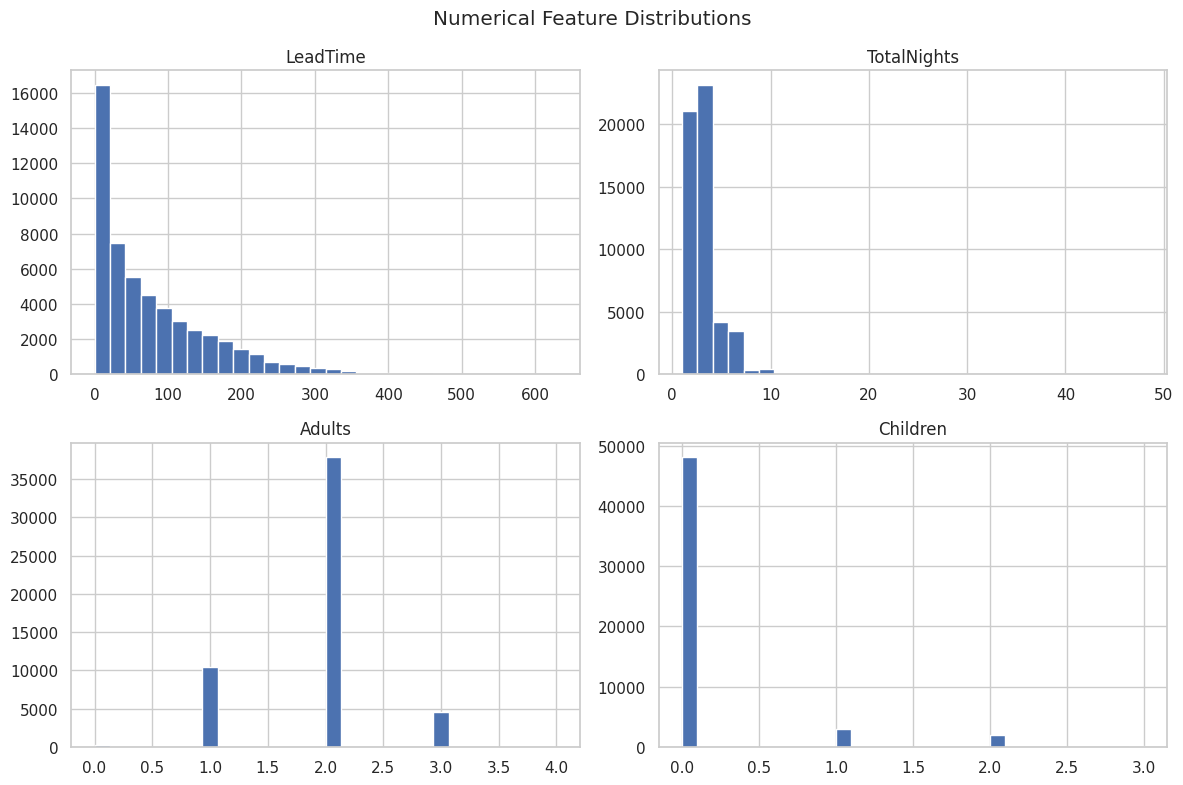

In [318]:

columns = ["LeadTime", "TotalNights", "Adults", "Children"]

df[columns].hist(figsize=(12, 8), bins=30)

plt.suptitle("Numerical Feature Distributions")
plt.tight_layout()
plt.savefig("outputs/histograms.png", bbox_inches="tight")
plt.show()



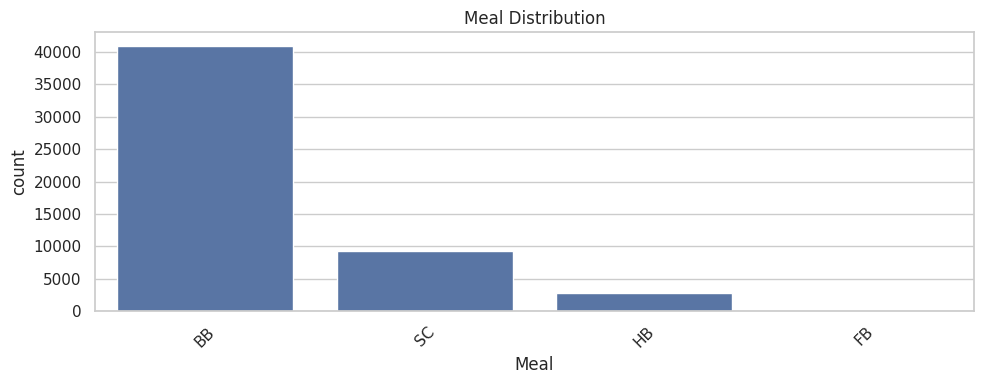

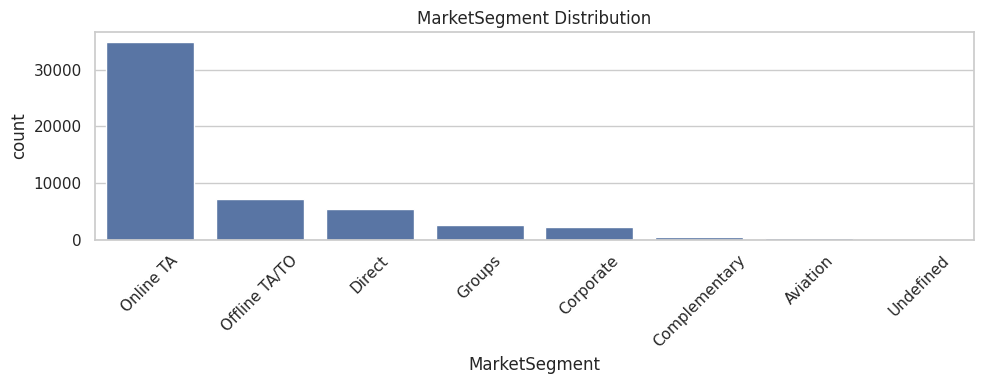

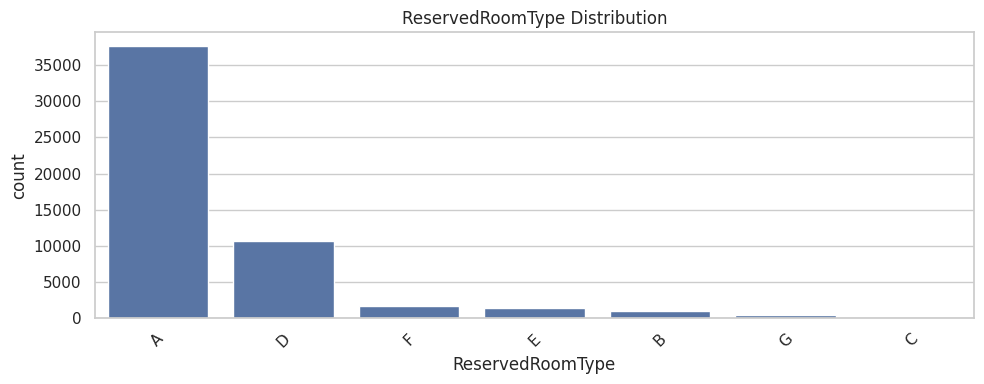

In [319]:

columns = ["Meal", "MarketSegment", "ReservedRoomType"]

for col in columns:
    plt.figure(figsize=(10, 4))

    sns.countplot(
        data=df,
        x=col,
        order=df[col].value_counts().index
    )

    plt.title(col + " Distribution")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.savefig(f"outputs/bar_{col}.png", bbox_inches="tight")
    plt.show()


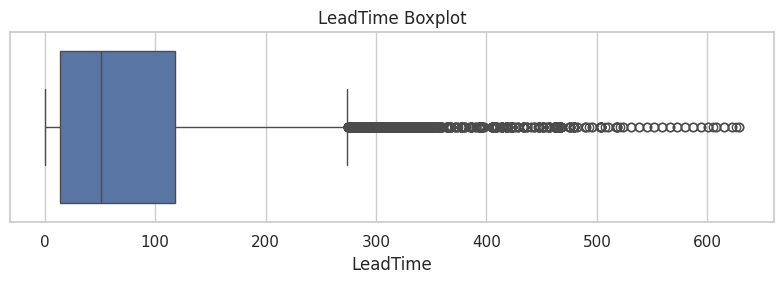

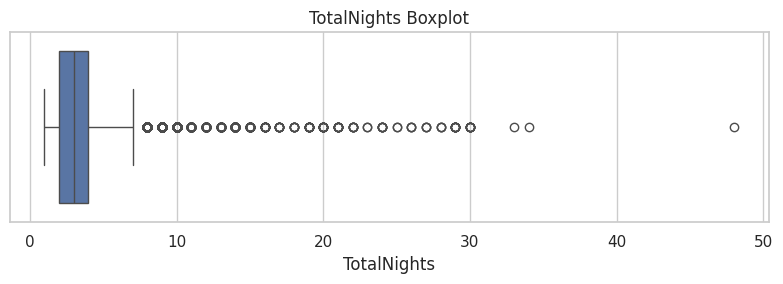

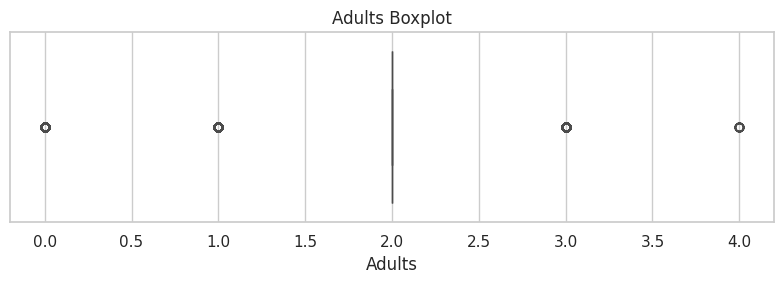

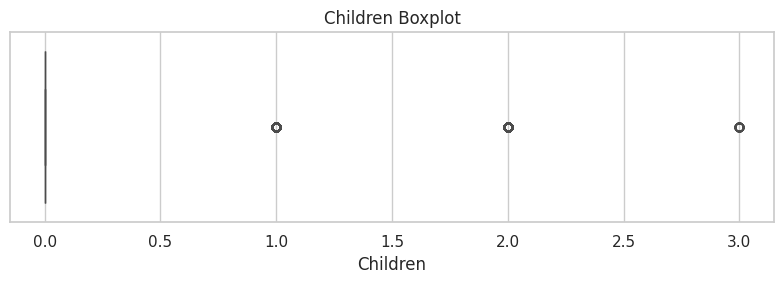

In [320]:


columns = ["LeadTime", "TotalNights", "Adults", "Children"]

for col in columns:
    plt.figure(figsize=(8, 3))

    sns.boxplot(x=df[col])

    plt.title(col + " Boxplot")
    plt.tight_layout()
    plt.savefig(f"outputs/boxplot_{col}.png", bbox_inches="tight")
    plt.show()



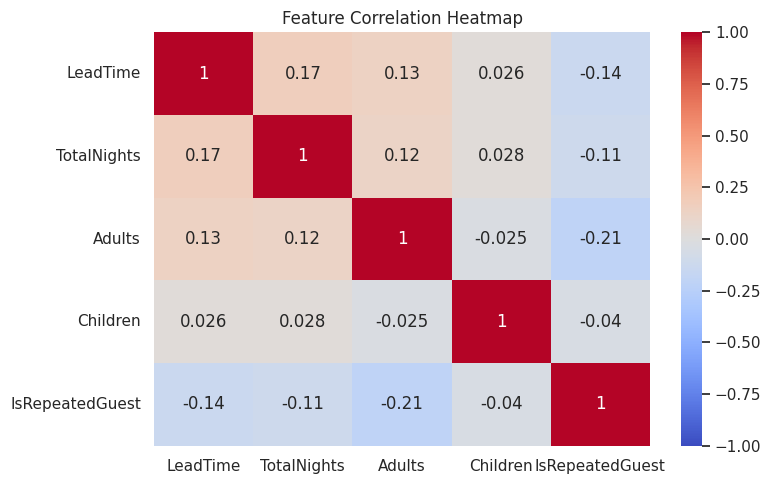

In [321]:

numeric_columns = [
    "LeadTime",
    "TotalNights",
    "Adults",
    "Children",
    "IsRepeatedGuest"
]

plt.figure(figsize=(8, 5))

sns.heatmap(
    df[numeric_columns].corr(),
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.savefig("outputs/heatmap.png", bbox_inches="tight")
plt.show()


In [322]:

print("Skewness:")
print(df[numeric_columns].skew())

print("\nNumerical statistics:")
display(df[numeric_columns].describe())

print("\nCategorical unique values:")
print(df[["Meal", "MarketSegment", "ReservedRoomType"]].nunique())

print("\nMost frequent categories:")
for col in ["Meal", "MarketSegment", "ReservedRoomType"]:
    print("\n", col)
    print(df[col].value_counts())


Skewness:
LeadTime           1.572938
TotalNights        3.241266
Adults            -0.235516
Children           3.481110
IsRepeatedGuest    5.606296
dtype: float64

Numerical statistics:


,LeadTime,TotalNights,Adults,Children,IsRepeatedGuest
count,53043.000000,53043.000000,53043.000000,53039.000000,53043.000000
mean,78.042249,3.155628,1.882718,0.132544,0.029071
std,82.135822,2.035887,0.535483,0.443288,0.168006
min,0.000000,1.000000,0.000000,0.000000,0.000000
25%,14.000000,2.000000,2.000000,0.000000,0.000000
50%,51.000000,3.000000,2.000000,0.000000,0.000000
75%,118.000000,4.000000,2.000000,0.000000,0.000000
max,629.000000,48.000000,4.000000,3.000000,1.000000



Categorical unique values:
Meal                4
MarketSegment       8
ReservedRoomType    7
dtype: int64

Most frequent categories:

 Meal
Meal
BB    40984
SC     9274
HB     2774
FB       11
Name: count, dtype: int64

 MarketSegment
MarketSegment
Online TA        34829
Offline TA/TO     7195
Direct            5483
Groups            2615
Corporate         2204
Complementary      493
Aviation           222
Undefined            2
Name: count, dtype: int64

 ReservedRoomType
ReservedRoomType
A    37652
D    10717
F     1749
E     1450
B      988
G      474
C       13
Name: count, dtype: int64


In [323]:

# Initial features selected based on booking behavior
numeric_features = [
    "LeadTime",
    "TotalNights",
    "Adults",
    "Children",
    "IsRepeatedGuest"
]

categorical_features = [
    "Meal",
    "MarketSegment",
    "ReservedRoomType"
]

# Correlation filter
corr = df[numeric_features].corr().abs()

to_remove = []

for i in range(len(numeric_features)):
    for j in range(i):
        if corr.iloc[i, j] > 0.90:
            if numeric_features[i] not in to_remove:
                to_remove.append(numeric_features[i])

# Remove highly correlated features
numeric_features = [
    col for col in numeric_features if col not in to_remove
]

features = numeric_features + categorical_features

X = df[features].copy()

print("Removed by correlation filter:", to_remove)
print("Selected features:", features)
print("Number of selected features:", len(features))


Removed by correlation filter: []
Selected features: ['LeadTime', 'TotalNights', 'Adults', 'Children', 'IsRepeatedGuest', 'Meal', 'MarketSegment', 'ReservedRoomType']
Number of selected features: 8


In [324]:

# Outlier handling
class CapOutliers(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        self.limits = X[["LeadTime", "TotalNights"]].quantile(0.99)
        return self

    def transform(self, X):
        X = X.copy()

        for col in self.limits.index:
            X[col] = X[col].clip(upper=self.limits[col])

        return X


# Numerical pipeline
numeric_pipeline = Pipeline([
    ("missing", SimpleImputer(strategy="median")),
    ("scaling", StandardScaler())
])

# Categorical pipeline
categorical_pipeline = Pipeline([
    ("missing", SimpleImputer(strategy="most_frequent")),
    ("encoding", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Combine both pipelines
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# Complete preprocessing pipeline
pipeline = Pipeline([
    ("outliers", CapOutliers()),
    ("preprocessing", preprocessor),
    ("filter", VarianceThreshold(threshold=0))
])

# Fit and transform the data
X_processed = pipeline.fit_transform(X)

print("Original shape:", X.shape)
print("Processed shape:", X_processed.shape)
print("Missing values:", np.isnan(X_processed).sum())


Original shape: (53043, 8)
Processed shape: (53043, 24)
Missing values: 0


In [325]:

print("Processed rows:", X_processed.shape[0])
print("Processed features:", X_processed.shape[1])

assert np.isfinite(X_processed).all()
assert X_processed.shape[0] == len(X)


Processed rows: 53043
Processed features: 24


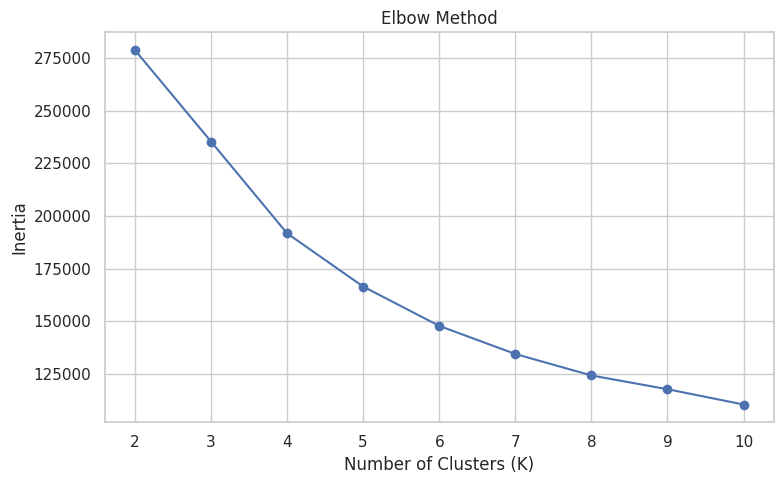

In [326]:

inertias = []

K_values = range(2, 11)

for k in K_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_processed)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))

plt.plot(K_values, inertias, marker="o")

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")

plt.tight_layout()
plt.savefig("outputs/elbow_method.png", bbox_inches="tight")
plt.show()


In [327]:

results = []

for k in range(2, 7):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_processed)

    silhouette = silhouette_score(
        X_processed,
        labels,
        sample_size=2000,
        random_state=42
    )

    dbi = davies_bouldin_score(X_processed, labels)

    results.append([k, silhouette, dbi])

results_df = pd.DataFrame(
    results,
    columns=["K", "Silhouette", "Davies-Bouldin"]
)

display(results_df.round(3))


,K,Silhouette,Davies-Bouldin
0,2,0.563,0.567
1,3,0.201,1.609
2,4,0.219,1.387
3,5,0.239,1.313
4,6,0.249,1.209


In [328]:

K = 3

kmeans_pipeline = Pipeline([
    ("preprocessing", pipeline),
    ("model", KMeans(
        n_clusters=K,
        random_state=42,
        n_init=10
    ))
])

# Train the clustering model
clusters = kmeans_pipeline.fit_predict(X)

# Get processed data from the fitted pipeline
X_processed = kmeans_pipeline.named_steps["preprocessing"].transform(X)

# Add cluster labels to the dataset
df["Cluster"] = clusters

print("Cluster sizes:")
print(df["Cluster"].value_counts().sort_index())



Cluster sizes:
Cluster
0    21844
1    29657
2     1542
Name: count, dtype: int64


In [329]:

silhouette = silhouette_score(
    X_processed,
    clusters,
    sample_size=2000,
    random_state=42
)

dbi = davies_bouldin_score(X_processed, clusters)

print("Number of clusters:", K)
print("Silhouette Score:", round(silhouette, 3))
print("Davies-Bouldin Index:", round(dbi, 3))



Number of clusters: 3
Silhouette Score: 0.201
Davies-Bouldin Index: 1.609


In [330]:

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_processed)

print("PC1 explained variance:",
      round(pca.explained_variance_ratio_[0], 3))

print("PC2 explained variance:",
      round(pca.explained_variance_ratio_[1], 3))

print("Total explained variance:",
      round(pca.explained_variance_ratio_.sum(), 3))


PC1 explained variance: 0.242
PC2 explained variance: 0.164
Total explained variance: 0.405


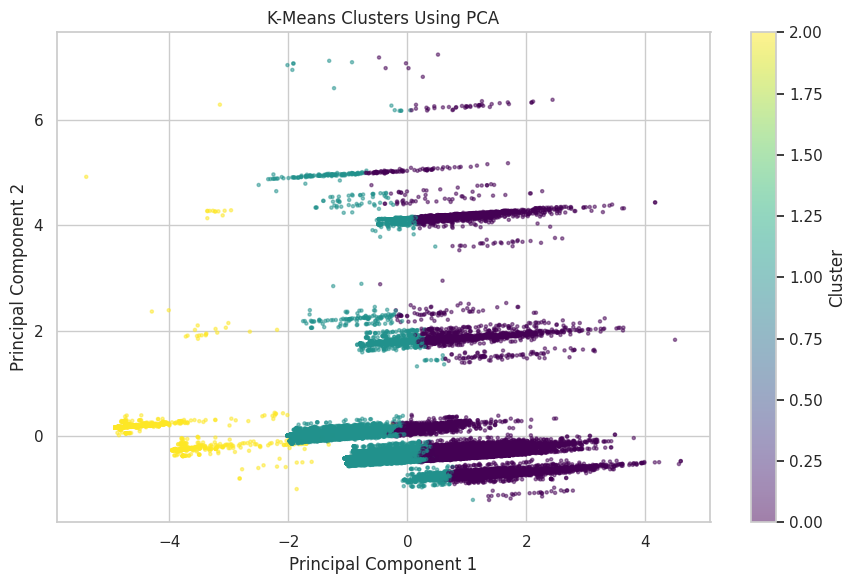

In [331]:


plt.figure(figsize=(9, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=clusters,
    cmap="viridis",
    s=5,
    alpha=0.5
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clusters Using PCA")
plt.colorbar(label="Cluster")

plt.tight_layout()
plt.savefig("outputs/pca_clusters.png", bbox_inches="tight")
plt.show()


In [332]:

# Numerical characteristics
cluster_summary = df.groupby("Cluster")[
    ["LeadTime", "TotalNights", "Adults", "Children"]
].mean().round(2)

print("Average numerical values:")
display(cluster_summary)

# Categorical characteristics
for col in ["Meal", "MarketSegment", "ReservedRoomType"]:

    print("\n", col)

    display(
        pd.crosstab(
            df["Cluster"],
            df[col],
            normalize="index"
        ).round(2)
    )


Average numerical values:


,LeadTime,TotalNights,Adults,Children
Cluster,,,,
0,140.03,4.33,2.11,0.21
1,35.80,2.36,1.75,0.08
2,12.33,1.81,1.24,0.03



 Meal


Meal,BB,FB,HB,SC
Cluster,,,,
0,0.81,0.0,0.07,0.12
1,0.74,0.0,0.04,0.23
2,0.95,0.0,0.01,0.04



 MarketSegment


MarketSegment,Aviation,Complementary,Corporate,Direct,Groups,Offline TA/TO,Online TA,Undefined
Cluster,,,,,,,,
0,0.00,0.00,0.00,0.07,0.04,0.14,0.74,0.0
1,0.00,0.01,0.04,0.13,0.05,0.14,0.63,0.0
2,0.04,0.13,0.57,0.10,0.01,0.05,0.10,0.0



 ReservedRoomType


ReservedRoomType,A,B,C,D,E,F,G
Cluster,,,,,,,
0,0.59,0.03,0.0,0.29,0.04,0.05,0.01
1,0.80,0.01,0.0,0.15,0.02,0.02,0.01
2,0.82,0.01,0.0,0.10,0.03,0.02,0.02


In [333]:

print("Total rows:", len(df))
print("Processed rows:", len(X_processed))
print("Cluster labels:", len(clusters))
print("Number of clusters:", df["Cluster"].nunique())

print("\nMissing cluster labels:")
print(df["Cluster"].isnull().sum())

assert len(df) == len(X_processed)
assert len(df) == len(clusters)
assert df["Cluster"].nunique() == K
assert np.isfinite(X_processed).all()




Total rows: 53043
Processed rows: 53043
Cluster labels: 53043
Number of clusters: 3

Missing cluster labels:
0


In [334]:

df.to_csv(
    "outputs/clustered_bookings.csv",
    index=False
)

results_df.to_csv(
    "outputs/kmeans_scores.csv",
    index=False
)

cluster_summary.to_csv(
    "outputs/cluster_summary.csv"
)


print(os.listdir("outputs"))



['bar_MarketSegment.png', 'bar_ReservedRoomType.png', 'kmeans_scores.csv', 'elbow_method.png', 'boxplot_Adults.png', 'pca_clusters.png', 'cluster_summary.csv', 'bar_Meal.png', 'boxplot_LeadTime.png', 'boxplot_TotalNights.png', 'boxplot_Children.png', 'histograms.png', 'heatmap.png', 'clustered_bookings.csv']


In [335]:

import shutil
from google.colab import files

shutil.make_archive(
    "phase1_outputs",
    "zip",
    "outputs"
)

files.download("phase1_outputs.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>